# Control EEG SNR

In this notebook, we explore the effect of background activity on simulations of projected EEG signals. To do this, we implement a simple ground truth model with the following steps:
1. Select an active region in the brain.
2. Define a signal to apply to all active dipoles, and model background activity for passive dipoles, which is parameterized by a variance. The Signal-to-Noise Ratio (SNR) between the signal and background activity is calculated to evaluate the ground truth.
3. Project the ground truth onto EEG electrodes and evaluate the projected EEG signal by measuring the SNR at the electrodes.

We hypothesize that the EEG SNR is influenced by the variance applied to the background activity, as well as by the size of the active patch, which we will measure simply as the number of dipoles involved. Note that the number of dipoles is not an entirely accurate measure, since the surface area can vary depending on the spacing between dipoles. Therefore, be aware that if the dipole distribution differs, the results may also differ. <br>

In the first section of this notebook, the user can experiment with the model by trying various active patch sizes and different variances for the background activity. In the second section, we run multiple simulations and plot the EEG SNR against different ground truth SNR values and active patch sizes.

## 📦 Imports

In [347]:
import mindmap as mm 
import pyvista as pv
import pywt
import numpy as np
import mne
import seaborn as sns
import pandas as pd
import plotly.express as px

## 🧠 Data

In [ ]:
# configuration
sub = "vepcon_sub-10"
mm.io.read_config("../configurations/simf.yml")

data  = mm.io.read_dataset(sub, "eeg_coreg", "fwd_hr", "parc", "cras", "white", "bem")
sfreq = data["eeg_coreg"].info["sfreq"]

# parameters
duration = 1    # duration in seconds

## Visualize Data

#### 🌟 EEG Coregistration

In [148]:
pos  = mm.utils.get_ch_positions(data["eeg_coreg"])
head = data["bem"][0]

plotter = pv.Plotter()
plotter.add_mesh(pv.PolyData(pos), color="red")
plotter.add_mesh(mm.utils.surf_to_polydata(head["rr"], head["tris"]))
plotter.show()

Widget(value='<iframe src="http://localhost:37595/index.html?ui=P_0x7108465078c0_4&reconnect=auto" class="pyvi…

#### 🌟 Forward Solution

In [4]:
mm.viz.plot_leadfield(data["eeg_coreg"], data["fwd_hr"]).show()

    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]


Widget(value='<iframe src="http://localhost:37595/index.html?ui=P_0x71089dda0b60_1&reconnect=auto" class="pyvi…

## Section 1: Simulation Model

#### 🌟 Print list of brain regions

In [149]:
regions = data["parc"].get_clut()["Label name"].values
pos     = mm.utils.get_src_position(data["fwd_hr"]["src"])*1000 + data["cras"]
labels  = data["parc"].label_points(pos)


print("\033[94mList of regions: \033[0m")
print(np.unique(labels))

List of regions: 
['ctx-lh-bankssts_1' 'ctx-lh-bankssts_2' 'ctx-lh-bankssts_3'
 'ctx-lh-caudalanteriorcingulate_1' 'ctx-lh-caudalanteriorcingulate_2'
 'ctx-lh-caudalanteriorcingulate_3' 'ctx-lh-caudalmiddlefrontal_1'
 'ctx-lh-caudalmiddlefrontal_2' 'ctx-lh-caudalmiddlefrontal_3'
 'ctx-lh-caudalmiddlefrontal_4' 'ctx-lh-caudalmiddlefrontal_5'
 'ctx-lh-cuneus_1' 'ctx-lh-cuneus_2' 'ctx-lh-cuneus_3' 'ctx-lh-cuneus_4'
 'ctx-lh-entorhinal_1' 'ctx-lh-frontalpole_1' 'ctx-lh-fusiform_1'
 'ctx-lh-fusiform_2' 'ctx-lh-fusiform_3' 'ctx-lh-fusiform_4'
 'ctx-lh-fusiform_5' 'ctx-lh-fusiform_6' 'ctx-lh-fusiform_7'
 'ctx-lh-fusiform_8' 'ctx-lh-inferiorparietal_1'
 'ctx-lh-inferiorparietal_10' 'ctx-lh-inferiorparietal_11'
 'ctx-lh-inferiorparietal_12' 'ctx-lh-inferiorparietal_2'
 'ctx-lh-inferiorparietal_3' 'ctx-lh-inferiorparietal_4'
 'ctx-lh-inferiorparietal_5' 'ctx-lh-inferiorparietal_6'
 'ctx-lh-inferiorparietal_7' 'ctx-lh-inferiorparietal_8'
 'ctx-lh-inferiorparietal_9' 'ctx-lh-inferiortemporal_1'
 '

#### 🛠️ <font color=violet>Select a region and number of regions</font>
- The region (`starting_roi`) defines the location of the patch
- The number of regions (`n`) will roughtly define the patch size

In [367]:
starting_roi = ["ctx-lh-inferiorparietal_5"]
n = 2

#### ⚙️ <font color=green>Grow patch around selected region</font>

In [368]:
# find region neighbors
vertices  = np.vstack([data["white"][0][0], data["white"][1][0]])
triangles = np.vstack([data["white"][0][1], data["white"][1][1]+len(data["white"][0][0])])
neighbors = mm.utils.find_neighbor_regions([vertices, triangles], data["parc"], data["cras"])

# add neighbors until list of size n
regions_idx = set(np.argwhere(regions==starting_roi[0])[0])

while len(regions_idx) < n:
    neighborhood = neighbors[np.random.choice(list(regions_idx))]
    neighbor_idx = np.argwhere(neighborhood==1).squeeze()

    new_idx = np.random.choice(neighbor_idx)
    if regions[new_idx] in labels:
        regions_idx.add(new_idx)

roi = regions[list(regions_idx)]

#### 🛠️ <font color=violet>Select ratio between signal and background</font>
Background activity correspond to white noise while the signal is a standardized mexican hat.

In [369]:
snr = 5

#### 🌟 Visualize signal and background

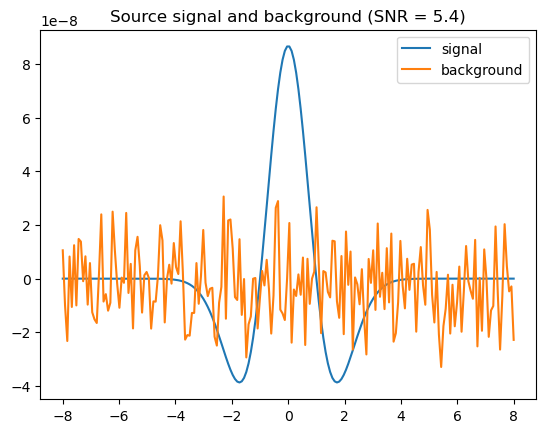

In [370]:
# signal
wavelet        = pywt.ContinuousWavelet("mexh")
[signal, time] = wavelet.wavefun(level=5, length=int(sfreq*duration))
signal         = signal*10**(-7)    # scale to nA

# relate source SNR to background variance
Ps  = np.sum((signal - signal.mean())**2)/len(signal)         # Average power of signal
a   = 1/(1-(1/len(signal)))
std = np.sqrt(a*Ps*10**(-snr/10))

# background
background = np.random.normal(scale=std, size=(data["fwd_hr"]["nsource"], int(data["eeg_coreg"].info["sfreq"])))        # make it brown signal

# source snr
snr = mm.utils.compute_snr(signal, background[0,:])

# plot
ax1 = sns.lineplot(x=time, y=signal, label="signal")
ax2 = sns.lineplot(x=time, y=background[0,:], label="background")
_   = ax1.set_title(f"Source signal and background (SNR = {snr[0]:.2})")

#### 🌟 Visualize ground truth

In [371]:
# generate ground truth
roi_mask     = np.isin(labels, roi)
brain_signal = background
brain_signal[roi_mask] = signal

vertices     = [data["fwd_hr"]["src"][0]["vertno"], data["fwd_hr"]["src"][1]["vertno"]]
brain_signal = mne.SourceEstimate(brain_signal, vertices, tmin=0, tstep=1/sfreq, subject=sub)

# plot
mm.viz.plot_brain_time_series(data["fwd_hr"]["src"], brain_signal.data, sfreq=sfreq)

Widget(value='<iframe src="http://localhost:37595/index.html?ui=P_0x71083b889940_48&reconnect=auto" class="pyv…

#### ⚙️ <font color=green> Project ground truth to EEG electrodes </font>

In [372]:
eeg     = mne.apply_forward(data["fwd_hr"], brain_signal, data["eeg_coreg"].info, verbose="warning")
eeg_snr = mm.utils.compute_eeg_snr(brain_signal, data["fwd_hr"], roi_mask)

#### 🌟 Visualize EEG

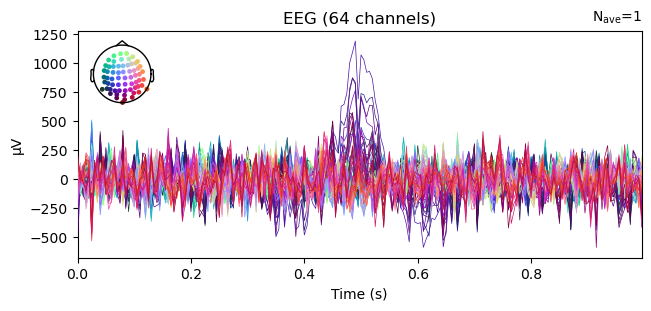

In [373]:
#%matplotlib qt
_ = eeg.plot()

SNR topomap
Minimum SNR: -55.43531501507786
Maximum SNR: -0.2759700897197598


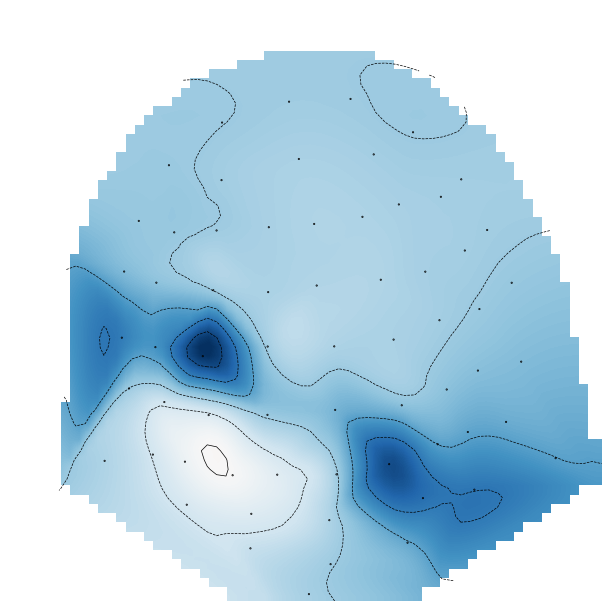

In [331]:
print(f"SNR topomap")
print(f"Minimum SNR: {np.min(eeg_snr)}")
print(f"Maximum SNR: {np.max(eeg_snr)}")
_ = mne.viz.plot_topomap(eeg_snr, data["eeg_coreg"].info, size=6, outlines=None, extrapolate="local")

## Section 2: Model Evaluation
🚨 Run cell '📦 imports' and '🧠 data' before continuing. 

Run the model multiple times for various patch sizes and background variations.

#### 🛠️ <font color=violet>Select loop parameters</font>

In [384]:
rg_num_dipoles = [20, 100]     # range for the number of dipoles (defines patch size)
rg_s_snr       = [1, 10]      # range for the SNR in the sources (1 signal over 1 background)
rep            = 3000         # number of repetition

#### Preparing data

In [ ]:
# storage
n_dipoles  = np.zeros(rep)                                        # number of dipoles (roughthly patch size)
source_snr = np.zeros(rep)                                        # source SNR (1 signal over 1 background)
eeg_snr    = np.zeros((rep, len(data["eeg_coreg"].ch_names)))     # eeg SNR (1 SNR per electrode)

# vertno (to select dipole and instanciate mne.SourceEstimate)
vertno = [data["fwd_hr"]["src"][0]["vertno"], data["fwd_hr"]["src"][1]["vertno"]]

# dipole distance matrix (to grow dipole patch)
dist = [
    data["fwd_hr"]["src"][0]["dist"][vertno[0]][:,vertno[0]], 
    data["fwd_hr"]["src"][1]["dist"][vertno[1]][:,vertno[1]],
]

# signal (for active dipoles)
wavelet     = pywt.ContinuousWavelet("mexh")
[signal, _] = wavelet.wavefun(level=5, length=int(sfreq*duration))
signal      = signal*10**(-7)

# function relating source SNR to background variance
Ps = np.sum((signal - signal.mean())**2)/len(signal)         # Average power of signal
a  = 1/(1-(1/len(signal)))  

compute_std = lambda snr: np.sqrt(a*Ps*10**(-snr/10))

#### ⚙️ <font color=green>Loop through simulations</font>

In [386]:
for i in range(rep):
    # select state
    n     = np.random.randint(rg_num_dipoles[0], rg_num_dipoles[1])
    s_snr = np.random.uniform(rg_s_snr[0], rg_s_snr[1])

    # generate patch
    hemi            = np.random.choice([0,1])                    # choose hemisphere (left or right)
    starting_dipole = np.random.choice(vertno[hemi])             # choose starting dipole
    starting_idx    = np.argwhere(vertno[hemi]==starting_dipole)[0]
    
    ddist = dist[hemi][starting_idx].todense().squeeze()    # distance between dipoles and selected dipole
    roi   = np.argsort(ddist)[:n]                           # choose n closest dipoles (includes selected dipole)
    
    if hemi == 1: 
        roi = roi + data["fwd_hr"]["src"][0]["nuse"]     # roi index of right hemisphere start after left hemisphere

    roi_mask = np.zeros(data["fwd_hr"]["nsource"], dtype=bool)
    roi_mask[roi] = True
    
    # generate background
    std        = compute_std(s_snr)
    background = np.random.normal(scale=std, size=(data["fwd_hr"]["nsource"], int(data["eeg_coreg"].info["sfreq"])))      # make it brown signal

    # generate ground truth
    brain_signal      = background
    brain_signal[roi] = signal
    brain_signal      = mne.SourceEstimate(brain_signal, vertno, tmin=0, tstep=1/sfreq, subject=sub)

    # store number of dipole, source snr and eeg snr
    n_dipoles[i]  = len(roi)
    source_snr[i] = mm.utils.compute_snr(signal, background[0,:])[0]
    eeg_snr[i,:]  = mm.utils.compute_eeg_snr(brain_signal, data["fwd_hr"], roi_mask)

#### 🌟 Visualize distributions

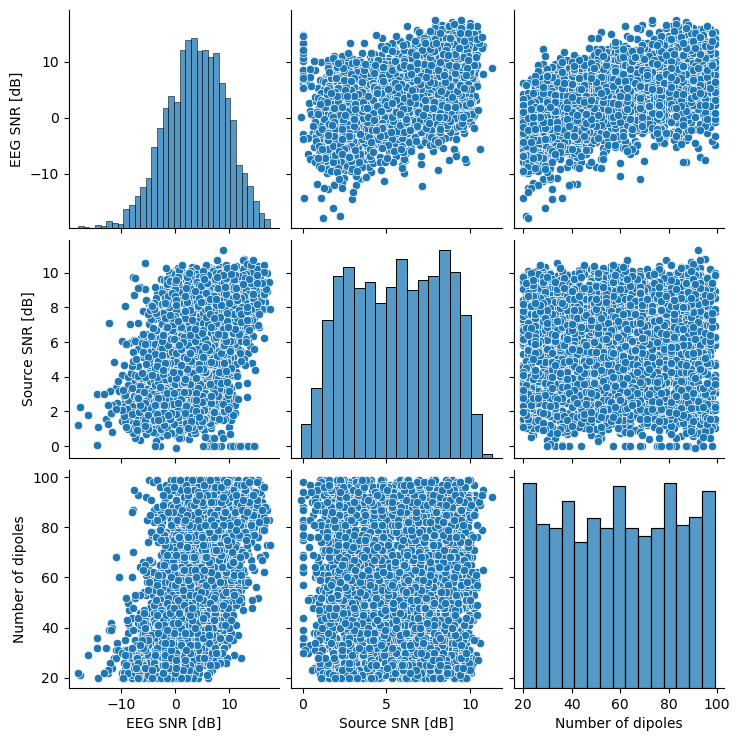

In [387]:
eeg_snr_max = np.max(eeg_snr, axis=1)
results = pd.DataFrame({"EEG SNR [dB]":eeg_snr_max, "Source SNR [dB]":source_snr, "Number of dipoles":n_dipoles})
_ = sns.pairplot(results)

#### 🌟 Visualize 3D scatter of EEG SNR

In [388]:
results["in range"] = (eeg_snr_max > 2) & (eeg_snr_max < 10)
fig = px.scatter_3d(results, x="Source SNR [dB]", y="Number of dipoles", z="EEG SNR [dB]", color="in range")
fig.update_traces(marker_size=10, marker_opacity=0.3)
fig.update_layout(width=1000, height=1000)
fig.show()